## Load data - setup

In [1]:
from statasetup import *


  ___  ____  ____  ____  ____ ®
 /__    /   ____/   /   ____/      18.0
___/   /   /___/   /   /___/       BE—Basic Edition

 Statistics and Data Science       Copyright 1985-2023 StataCorp LLC
                                   StataCorp
                                   4905 Lakeway Drive
                                   College Station, Texas 77845 USA
                                   800-STATA-PC        https://www.stata.com
                                   979-696-4600        stata@stata.com

Stata license: Unlimited-user network, expiring 17 Sep 2027
Serial number: 301909300944
  Licensed to: StataNow/BE 19.5
               StataNow/BE 19.5

Notes:
      1. Unicode is supported; see help unicode_advice.


This time do manually create the dataset


In [4]:
%%stata
* Create example dataset 1
input str1 Participant Score
"A" 2
"A" 3
"A" 2
"A" 3
"A" 2
"B" 5
"B" 6
"B" 5
"B" 6
"B" 5
"C" 8
"C" 9
"C" 8
"C" 9
"C" 8
end

* Create numeric participant ID
encode Participant, gen(id)
	


. * Create example dataset 1
. input str1 Participant Score

     Partici~t      Score
  1. "A" 2
  2. "A" 3
  3. "A" 2
  4. "A" 3
  5. "A" 2
  6. "B" 5
  7. "B" 6
  8. "B" 5
  9. "B" 6
 10. "B" 5
 11. "C" 8
 12. "C" 9
 13. "C" 8
 14. "C" 9
 15. "C" 8
 16. end

. 
. * Create numeric participant ID
. encode Participant, gen(id)

. 
. 


## 1. Step 1 - _observe the data by inspecting its plot_


. * Plot observations
. twoway scatter Score id, ///
>     jitter(3) ///
>     mcolor(%60) ///
>     msize(large) ///
>     xlabel(1 "A" 2 "B" 3 "C", labsize(vsmall)) ///
>     ylabel(1(1)10, labsize(vsmall)) ///
>     yscale(range(1 10)) ///
>     ytitle("Score") ///
>     xtitle("Participant") ///
>     graphregion(color(white)) ///
>         title("Example 1") ///
>         name(fig_example1, replace)

. 


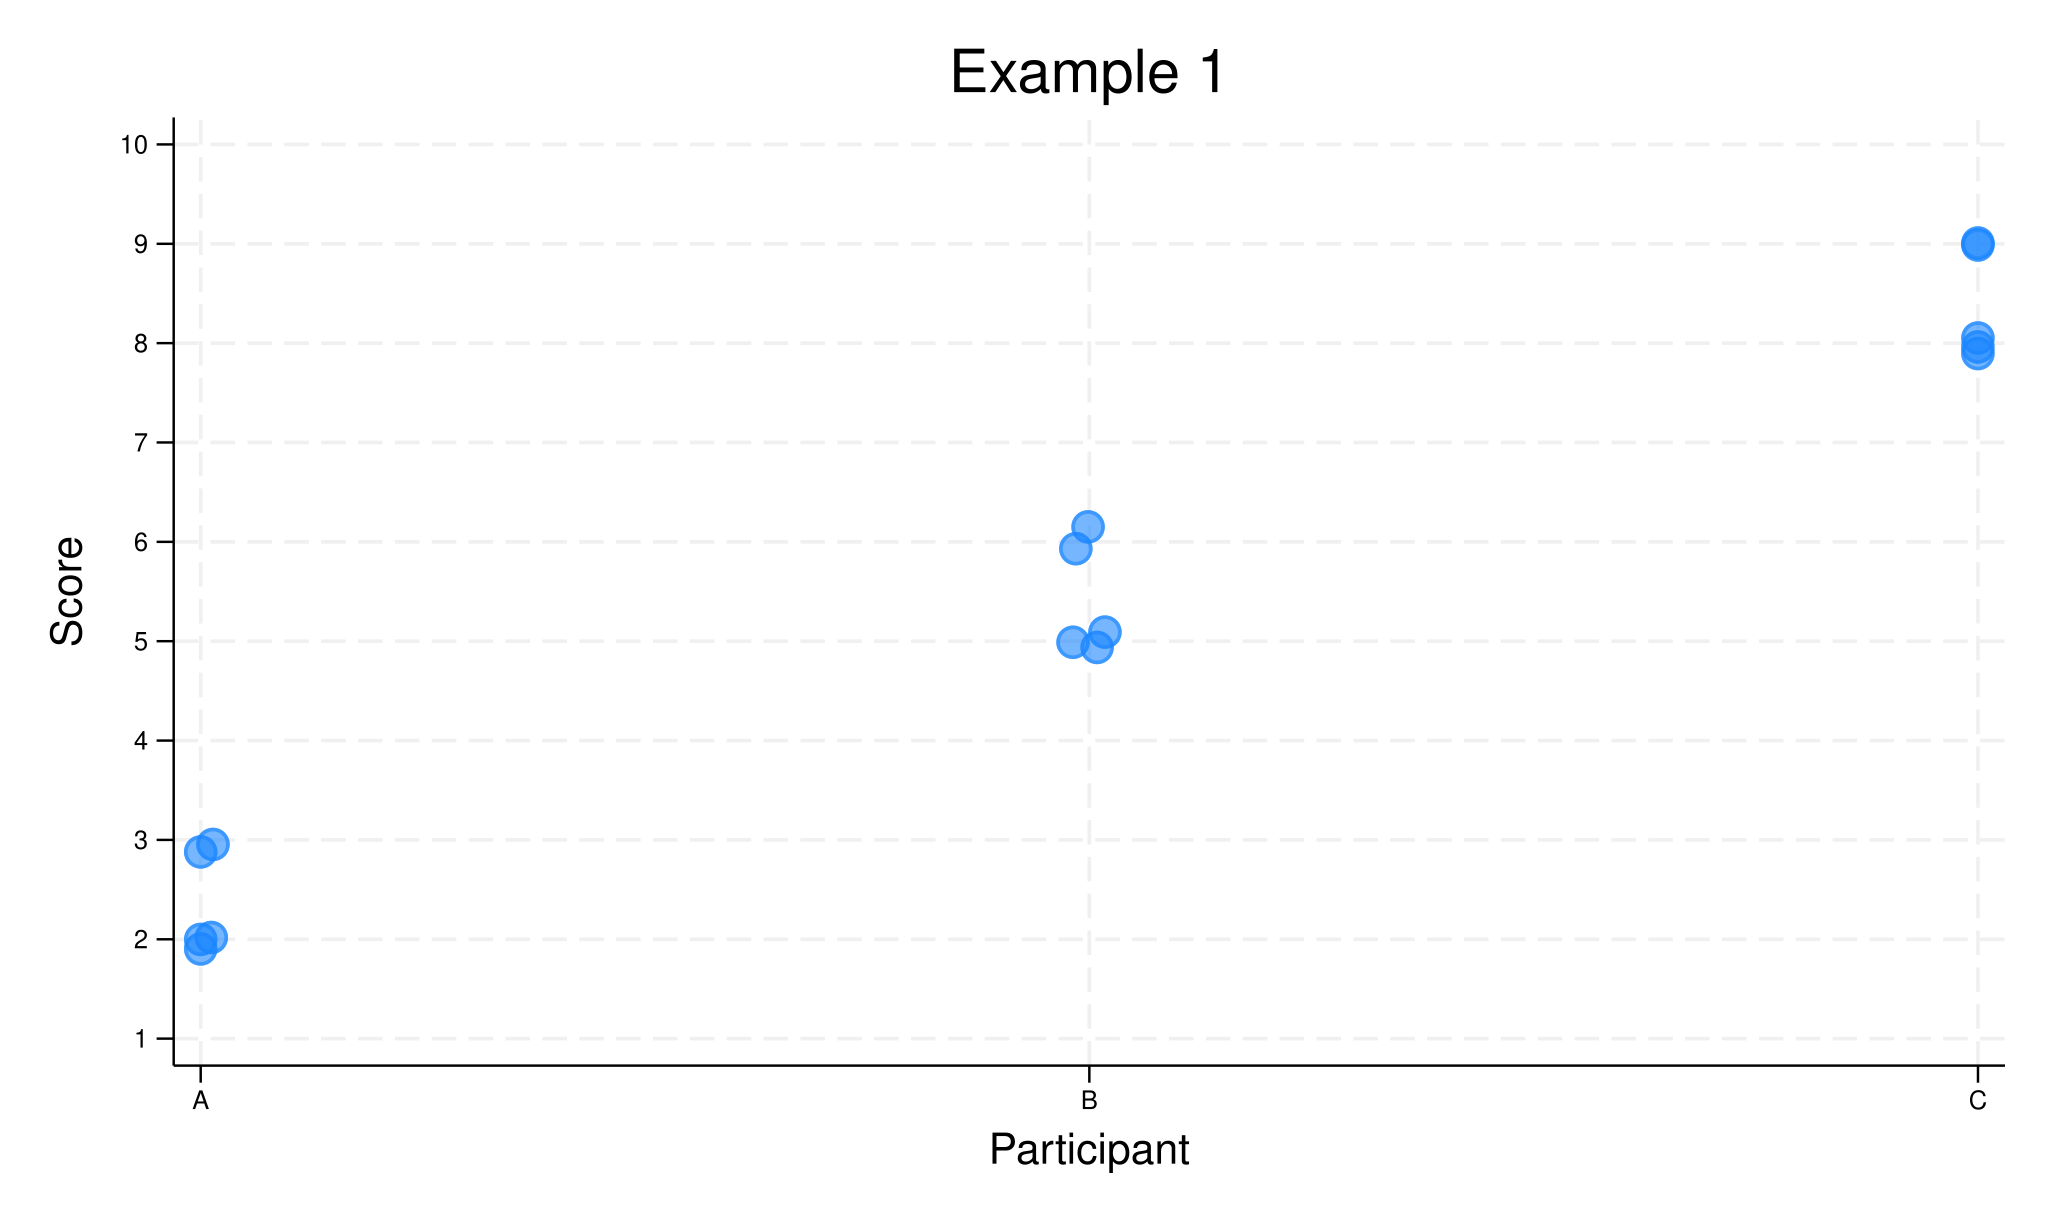

In [5]:
%%stata
* Plot observations
twoway scatter Score id, ///
    jitter(3) ///
    mcolor(%60) ///
    msize(large) ///
    xlabel(1 "A" 2 "B" 3 "C", labsize(vsmall)) ///
    ylabel(1(1)10, labsize(vsmall)) ///
    yscale(range(1 10)) ///
    ytitle("Score") ///
    xtitle("Participant") ///
    graphregion(color(white)) ///
	title("Example 1") ///
	name(fig_example1, replace)

## Step 2 - _calculate the ICC and interpret its plot_
1. if ICC >>0 then most of the variance can be attributed to between-group differences
2. otherwise there is high variation within the cluster group


I would expect a high ICC (so closer to 1.00) as the observations within participants are close
to each other. The between-participant differences are much larger than the within-participant
variation. Hence, most of the total variance seems to come from differences between
participants rather than differences in scores within participants

In [6]:
%%stata
* Estimate null model
mixed Score || Participant:

* Compute the ICC
estat icc


. * Estimate null model
. mixed Score || Participant:

Performing EM optimization ...

Performing gradient-based optimization: 
Iteration 0:  Log likelihood = -19.162037  
Iteration 1:  Log likelihood = -19.162037  

Computing standard errors ...

Mixed-effects ML regression                             Number of obs    =  15
Group variable: Participant                             Number of groups =   3
                                                        Obs per group:
                                                                     min =   5
                                                                     avg = 5.0
                                                                     max =   5
                                                        Wald chi2(0)     =   .
Log likelihood = -19.162037                             Prob > chi2      =   .

------------------------------------------------------------------------------
       Score | Coefficient  Std. err.      z   

## Step 3 - _fit a multilevel model with random intercept_

In [9]:
%%stata
import delimited "Datasets\df_GenAI_Productivity_Assignment.csv", clear

(encoding automatically selected: ISO-8859-1)
(4 vars, 500 obs)


### Step 3.1 - Data's plot


. twoway scatter productivity genai_time, ///
>     mcolor(navy%50) ///
>     msize(small) ///
>     xtitle("GenAI Time") ///
>     ytitle("Productivity") ///
>     xlabel(, labsize(vsmall)) ///
>     ylabel(1(1)10, labsize(vsmall)) ///
>     graphregion(color(white)) ///
>         name(fig_scatter_raw, replace)

. 


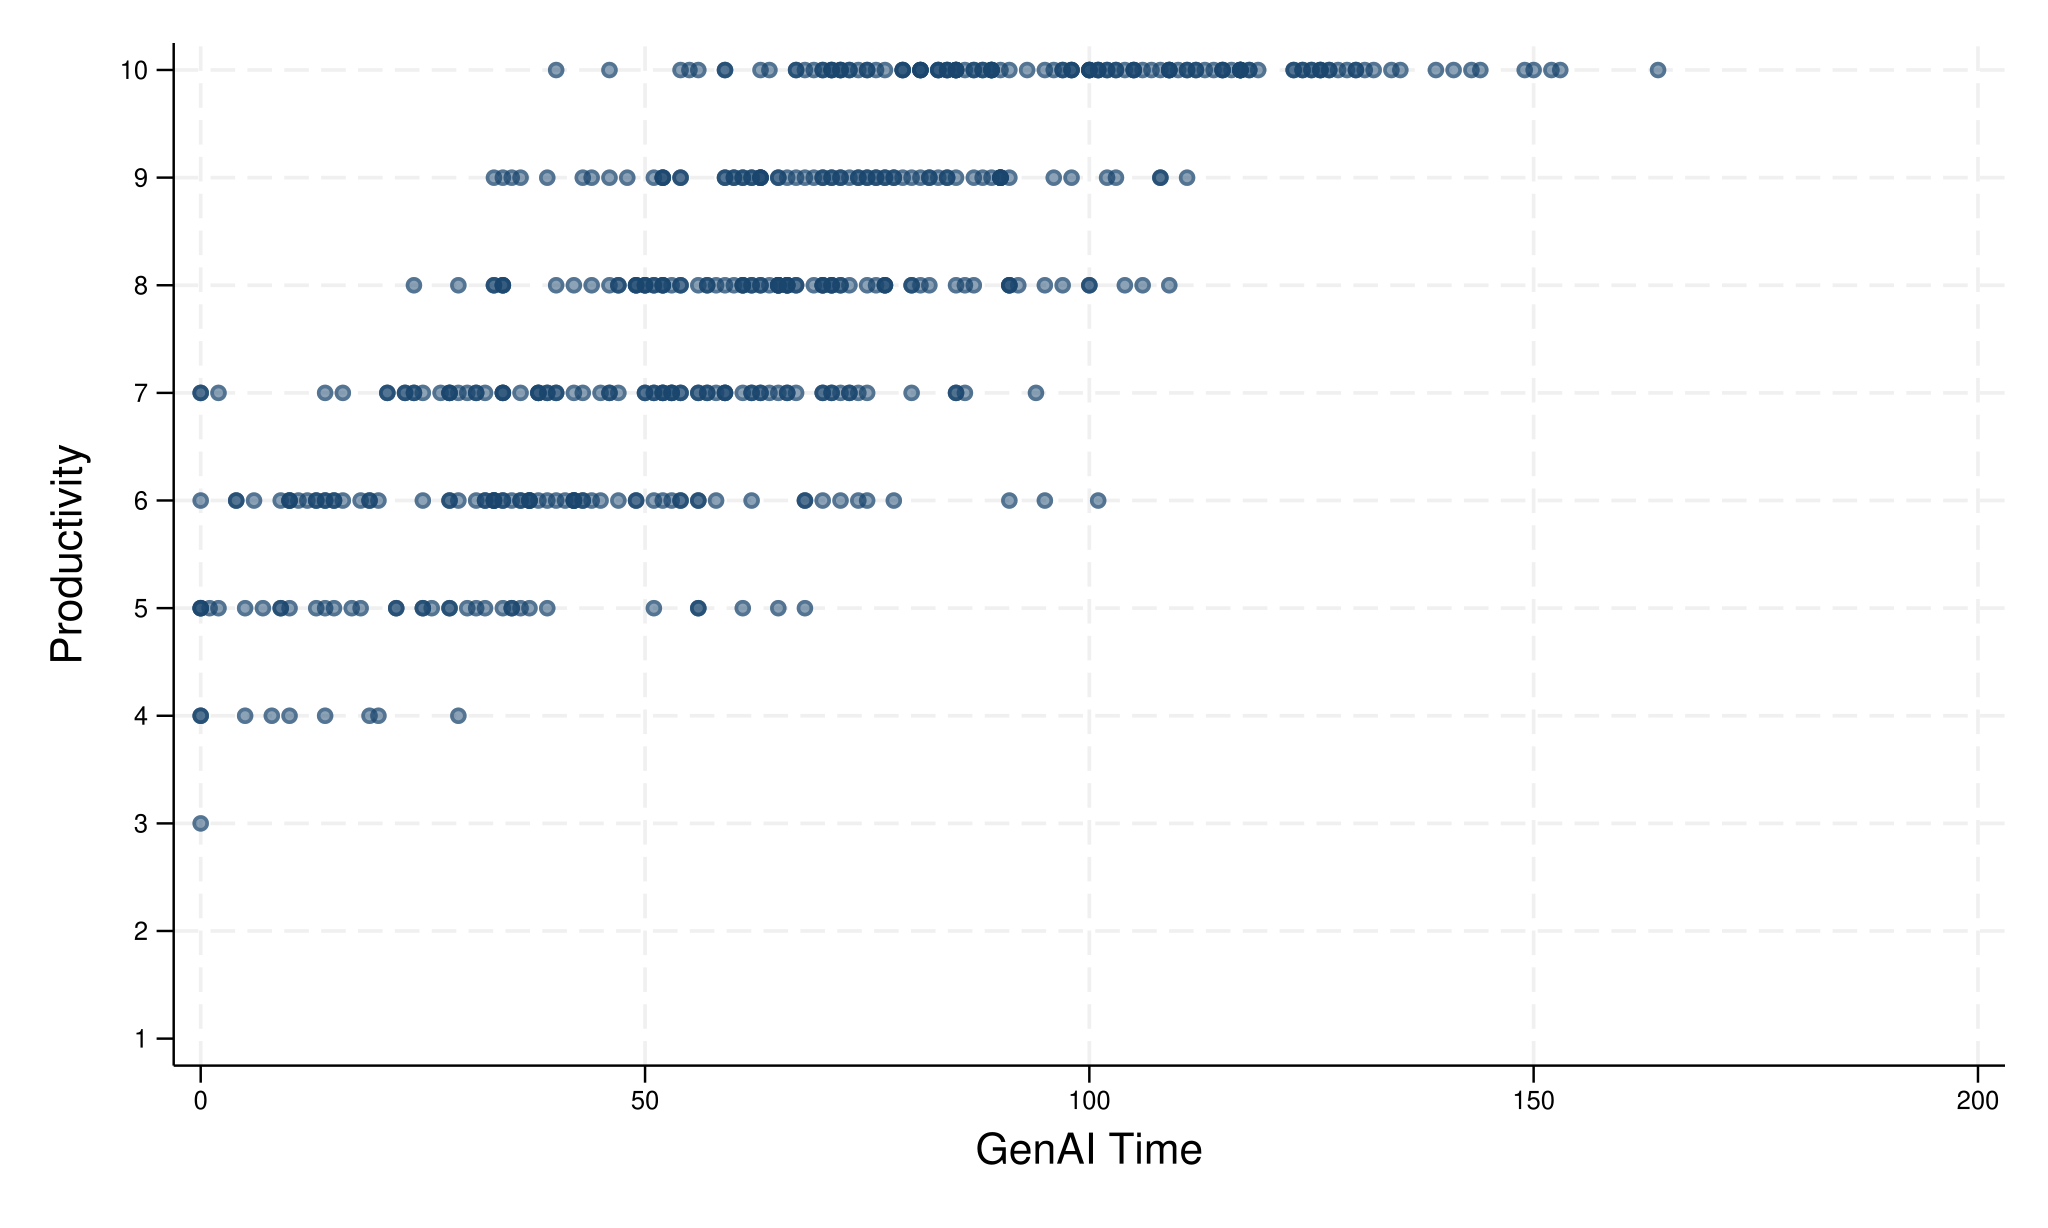

In [10]:
%%stata
twoway scatter productivity genai_time, ///
    mcolor(navy%50) ///
    msize(small) ///
    xtitle("GenAI Time") ///
    ytitle("Productivity") ///
    xlabel(, labsize(vsmall)) ///
    ylabel(1(1)10, labsize(vsmall)) ///
    graphregion(color(white)) ///
	name(fig_scatter_raw, replace)

### Step 3.2 Fit a multilevel model with productivity as outcome variable, GenAI_time as predictor variable, and user_id as a random intercept

The interpretation of the predictor variable `GenAI_time` in one sentence: _Time spent using GenAI was significantly and positively associated with self-reported
productivity (B = 0.034, SE = 0.002, Z = 19.81, p < .001)._

In [13]:
%%stata
* Regress productivity on genai_time, with user_id as random intercept
mixed productivity genai_time || user_id:


. * Regress productivity on genai_time, with user_id as random intercept
. mixed productivity genai_time || user_id:

Performing EM optimization ...

Performing gradient-based optimization: 
Iteration 0:  Log likelihood = -645.26986  
Iteration 1:  Log likelihood = -645.26986  

Computing standard errors ...

Mixed-effects ML regression                          Number of obs    =    500
Group variable: user_id                              Number of groups =     50
                                                     Obs per group:
                                                                  min =     10
                                                                  avg =   10.0
                                                                  max =     10
                                                     Wald chi2(1)     = 392.47
Log likelihood = -645.26986                          Prob > chi2      = 0.0000

------------------------------------------------------------------

### Step 3.3 - _separate between-person differences from within-person fluctuations in time spent on genAI_

In [ ]:
%%stata
drop genai_time_CM productivity_CM
* Compute cluster-mean scores (e.g., participant-specific means)
bysort user_id: egen genai_time_CM = mean(genai_time)
bysort user_id: egen productivity_CM = mean(productivity)

drop genai_time_C productivity_C
*Compute cluster-mean centered scores
gen genai_time_C = genai_time - genai_time_CM
gen productivity_C = productivity - productivity_CM




. drop genai_time_CM productivity_CM

. * Compute cluster-mean scores (e.g., participant-specific means)
. bysort user_id: egen genai_time_CM = mean(genai_time)

. bysort user_id: egen productivity_CM = mean(productivity)

. 
. *Compute cluster-mean centered scores
. gen genai_time_C = genai_time - genai_time_CM

. gen productivity_C = productivity - productivity_CM

. 


then Estimate a **WITHIN-BETWEEN** model

**interpretation**

1. 𝛾01: Participants who, on average, spent more time using GenAI per day tended to report
higher productivity than participants who spent less time using GenAI, on average (B = .043,
SE = .004, Z = 9.94, p < .01).
2. 𝛾10: On days when a participant spends one additional hour using GenAI compared to their
own average, their productivity is expected to be 0.03 points higher than usual.
(B = .03, SE = .002, Z = 17.47, p < .01).
Both associations are positive. Note that computing standardized parameter estimates would
facilitate comparison of the magnitude of the between-person and within-person associations.

In [19]:
%%stata
mixed productivity genai_time_CM genai_time_C || user_id:, mle
estimates store M2


. mixed productivity genai_time_CM genai_time_C || user_id:, mle

Performing EM optimization ...

Performing gradient-based optimization: 
Iteration 0:  Log likelihood =  -643.1581  
Iteration 1:  Log likelihood =  -643.1581  

Computing standard errors ...

Mixed-effects ML regression                          Number of obs    =    500
Group variable: user_id                              Number of groups =     50
                                                     Obs per group:
                                                                  min =     10
                                                                  avg =   10.0
                                                                  max =     10
                                                     Wald chi2(2)     = 403.85
Log likelihood =  -643.1581                          Prob > chi2      = 0.0000

------------------------------------------------------------------------------
productivity | Coefficient  Std. err.  

## Step 4 - inspect slope variations

In [21]:
%%stata
* Allow slope to vary across participants
mixed productivity genai_time_CM genai_time_C || user_id: genai_time_C, covariance(unstructured) mle
estimates store M3


. * Allow slope to vary across participants
. mixed productivity genai_time_CM genai_time_C || user_id: genai_time_C, covar
> iance(unstructured) mle

Performing EM optimization ...

Performing gradient-based optimization: 
Iteration 0:  Log likelihood =  -622.7305  
Iteration 1:  Log likelihood =  -622.7305  

Computing standard errors ...

Mixed-effects ML regression                          Number of obs    =    500
Group variable: user_id                              Number of groups =     50
                                                     Obs per group:
                                                                  min =     10
                                                                  avg =   10.0
                                                                  max =     10
                                                     Wald chi2(2)     = 237.33
Log likelihood =  -622.7305                          Prob > chi2      = 0.0000

---------------------------------